# 02 · Exploratory Data Analysis — FinSight AI
**Phase 2 · Subjects: DMW + ML** · KDD position: between *Step 4 (Transformation)* and *Step 5 (Mining)*: understand the data before mining it.

**Data:** Custom India synthetic **v1.1** (primary, graph structure injected, D-001/D-002) with **v1.0** as the control.
All figures are produced by `finsight.eda` (the same functions the batch pipeline runs), so the notebook and `reports/figures/` always agree.

> ⚠️ Synthetic data: findings describe the generator, not real-world fraud.

**Questions this notebook answers**
1. How are labels and scenarios distributed? Is accuracy a usable metric?
2. Do amount, channel, time or geography separate fraud?
3. **RQ1:** which transactional / behavioural / network features are most associated with fraud?
4. Why is BORDERLINE hard?
5. Did the v1.1 injection create *real* but *non-trivial* network signal?

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import display
from finsight import viz, eda, config
viz.apply_style()
pd.set_option("display.max_columns", 30, "display.width", 160)

m10, m11 = eda.load_master("v1_0"), eda.load_master("v1_1")
log = pd.read_csv(config.INDIA_V1_1_DIR / "injection_log.csv")
camo = eda.camouflaged_ids()
print(f"v1.1 master: {m11.shape[0]:,} rows × {m11.shape[1]} columns | camouflaged rows: {len(camo)}")

v1.1 master: 10,000 rows × 77 columns | camouflaged rows: 471


## 1 · Labels and scenarios

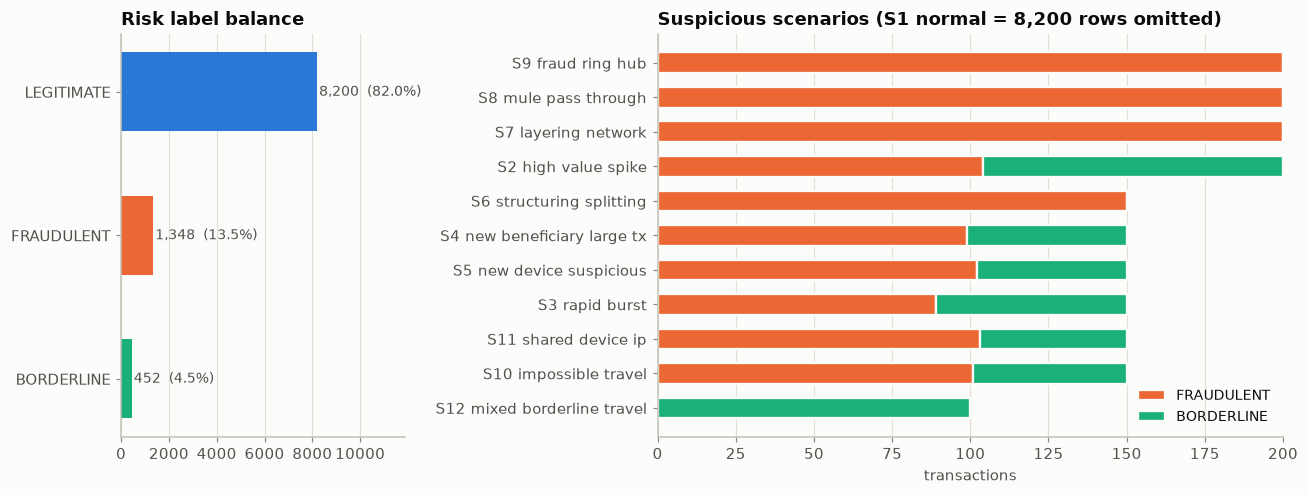

In [2]:
eda.fig_label_overview(m11);

- **82% LEGITIMATE / 13.5% FRAUDULENT / 4.5% BORDERLINE**. An always-"legit" model already scores **86.5% accuracy** on `is_fraud`, so accuracy is never the headline metric; we use **PR-AUC and F1** (Plan §7.1).
- S6–S9 (structuring, layering, mule, ring) are 100% FRAUDULENT; S12 is 100% BORDERLINE; the rest are mixed. BORDERLINE rows count as `is_fraud = 0`.

## 2 · Amount, channel, time, geography

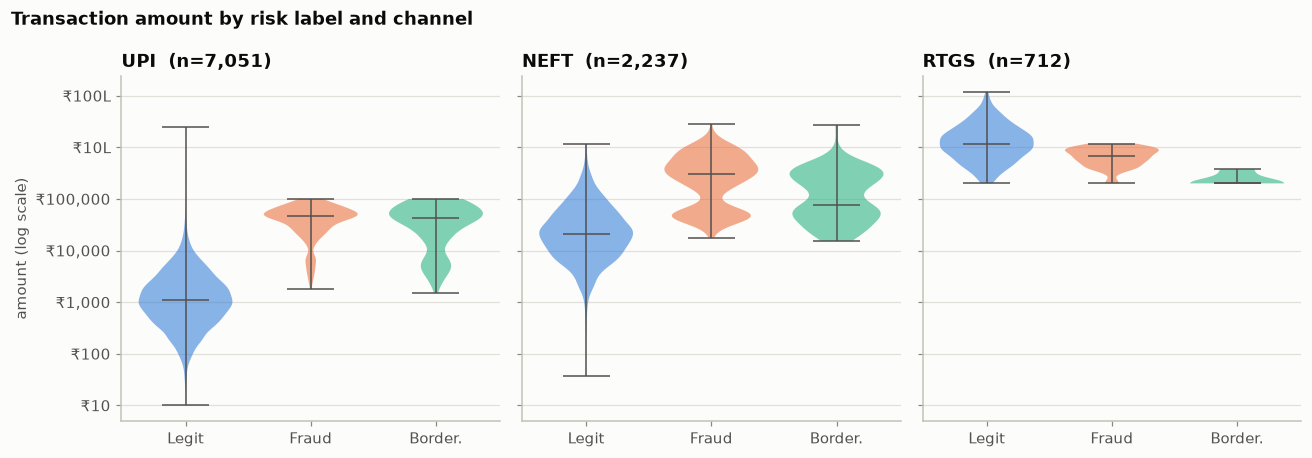

In [3]:
eda.fig_amount_by_label(m11);

- Within **UPI** and **NEFT**, fraud and borderline amounts sit roughly **1–2 orders of magnitude above** legitimate ones. UPI fraud piles up just below the ₹1 lakh UPI cap.
- In **RTGS** (≥ ₹2 lakh by rule) the pattern *reverses*: legitimate RTGS is larger. Amount only means something **relative to the channel/account**, which motivates `amount_ratio_vs_30d_avg` (Exp B).

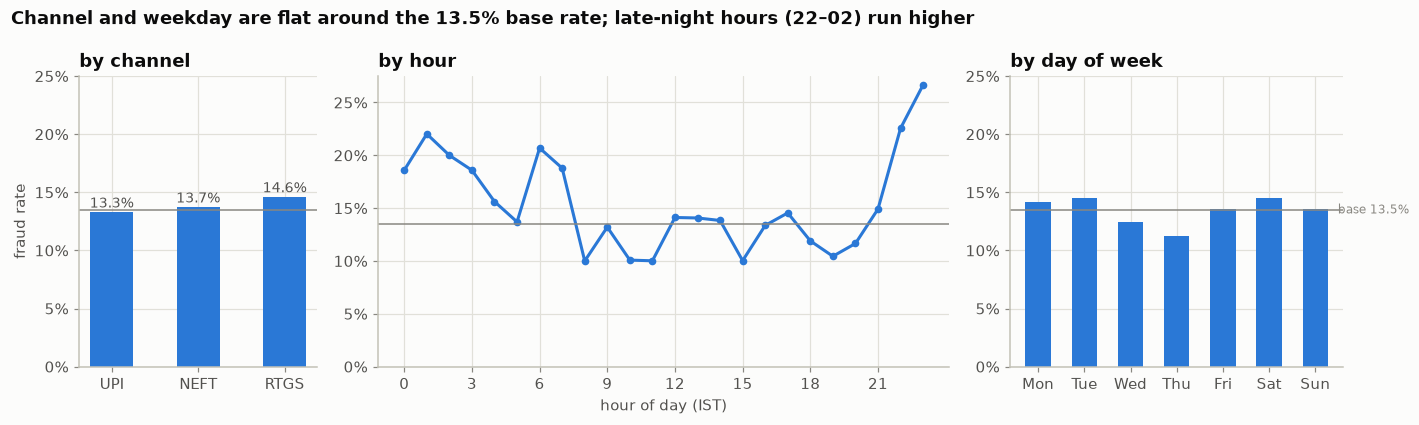

In [4]:
eda.fig_fraud_rate_time_channel(m11);

- Fraud rate by **channel** (13.3–14.6%) and **weekday** stays close to the 13.5% base rate, so channel alone carries no signal.
- **Hour of day** has a real but modest effect: late night (22:00–02:00) reaches **22–27%** vs ~10% at mid-morning, which is why `ODD_HOUR` is kept as a weak mining item (lift 1.45).

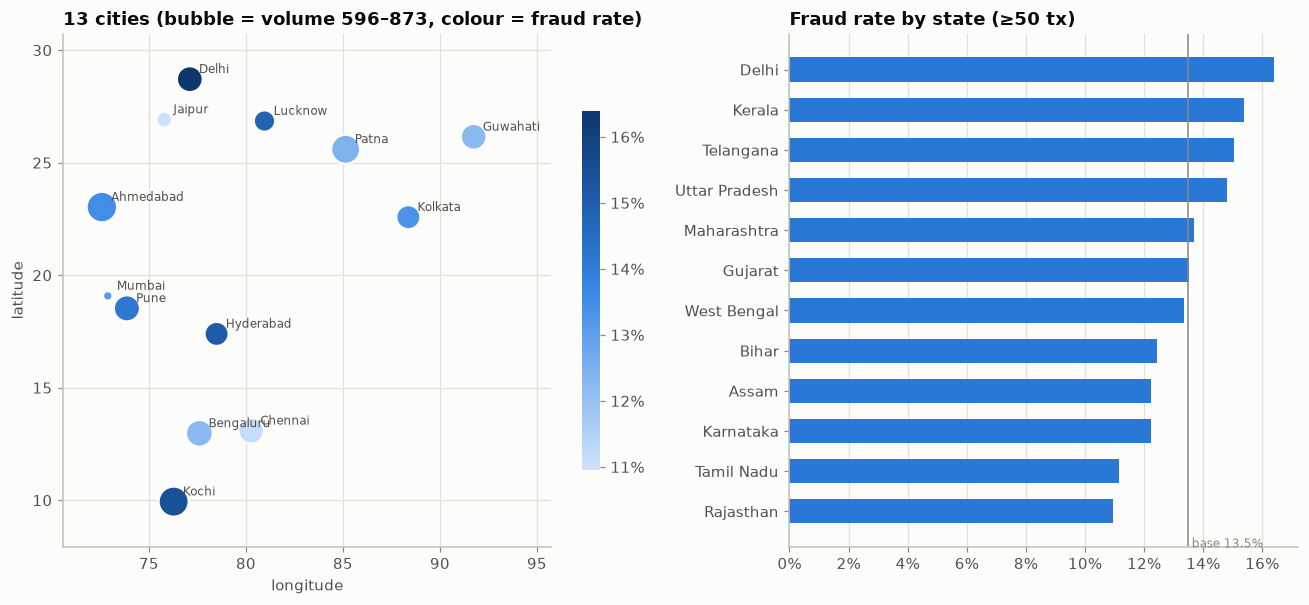

In [5]:
eda.fig_geo(m11);

- The 13 cities have similar volumes (596–873 tx). State fraud rates span **11%–16.5%** (Delhi highest, Rajasthan lowest): mild geographic variation, no geographic hotspot. Location matters only as **distance from the customer's home** (next section).

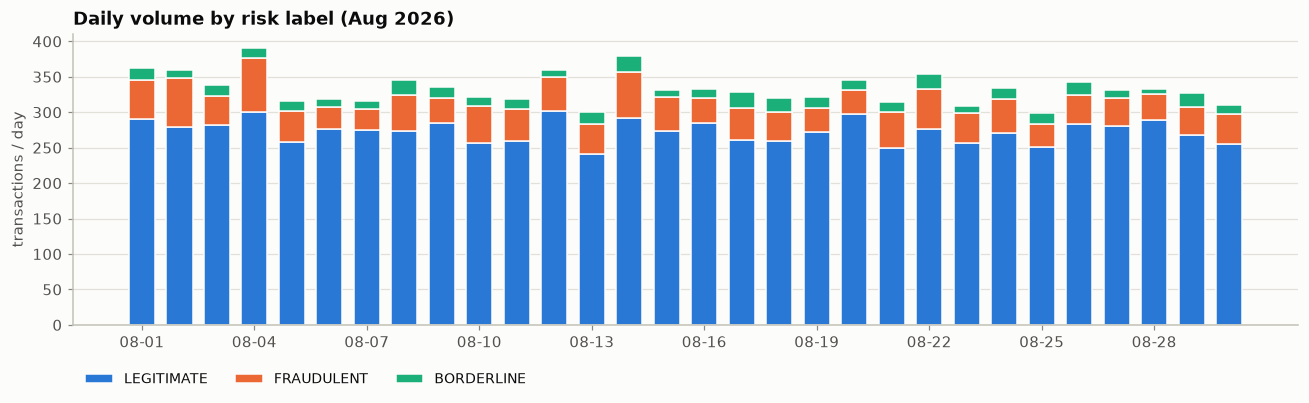

In [6]:
eda.fig_daily_volume(m11);

~300–390 transactions/day across 30 days with no trend and fraud spread throughout, so a **temporal hold-out** (train Aug 1–23, test Aug 24–30) is a fair robustness check for Phase 5.

## 3 · Behaviour flags (discretisation preview for Phase 4)

,flag,support,fraud_rate_given_flag,lift
0,NEW_DEVICE,0.2218,0.3206,2.38
1,NEW_BENEFICIARY,0.2444,0.2676,1.99
2,RECENT_BENEFICIARY (<24h),0.0906,0.7616,5.65
3,FAR_FROM_HOME (>100km),0.0575,0.6574,4.88
4,HIGH_AMOUNT_SPIKE (>5×),0.2683,0.3321,2.46
5,HIGH_VALUE (≥₹50k),0.1923,0.3500,2.60
6,NEAR_THRESHOLD (₹45–50k),0.0317,0.7287,5.41
7,ODD_HOUR (<6 or >22),0.1101,0.1953,1.45
8,PASS_THROUGH,0.0163,0.9939,7.37
9,SHARED_DEVICE (≥3 accts),0.0858,0.1981,1.47


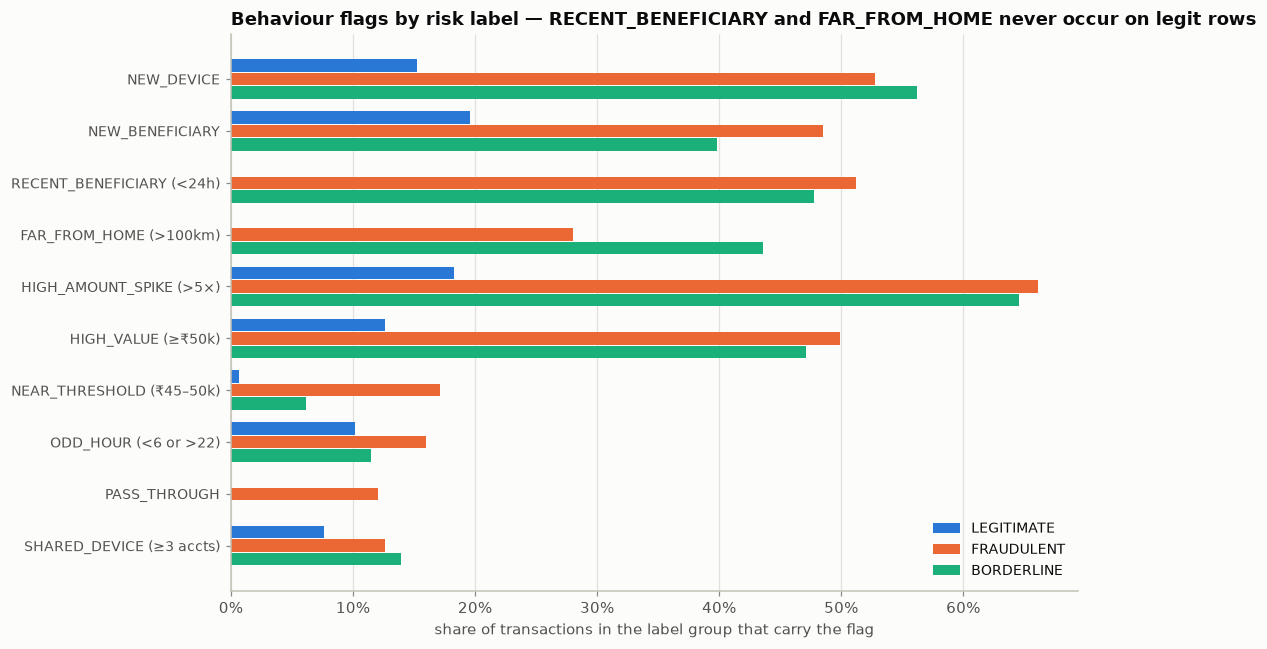

In [7]:
eda.fig_behaviour_flags(m11)
display(eda.flag_table(m11)[["flag", "support", "fraud_rate_given_flag", "lift"]])

- **RECENT_BENEFICIARY (<24h)** (lift 5.7) and **FAR_FROM_HOME (>100 km)** (lift 4.9) **never occur on legitimate rows**. This is a *generator artifact*: rules built on them will show very high confidence partly by construction, and the report must say so.
- **NEAR_THRESHOLD (₹45–50k)** has lift 5.4: the v1.1 structuring scenario (amounts kept just under ₹50k).
- **PASS_THROUGH** is the most precise flag (**99% fraud, lift 7.4**) but covers only 1.6% of rows. It's a classic mule indicator: high precision, low recall.
- **SHARED_DEVICE** and **ODD_HOUR** are weak (lift ≈ 1.5) because legitimate family devices (decoys) also share.

## 4 · Correlation and the RQ1 feature ranking

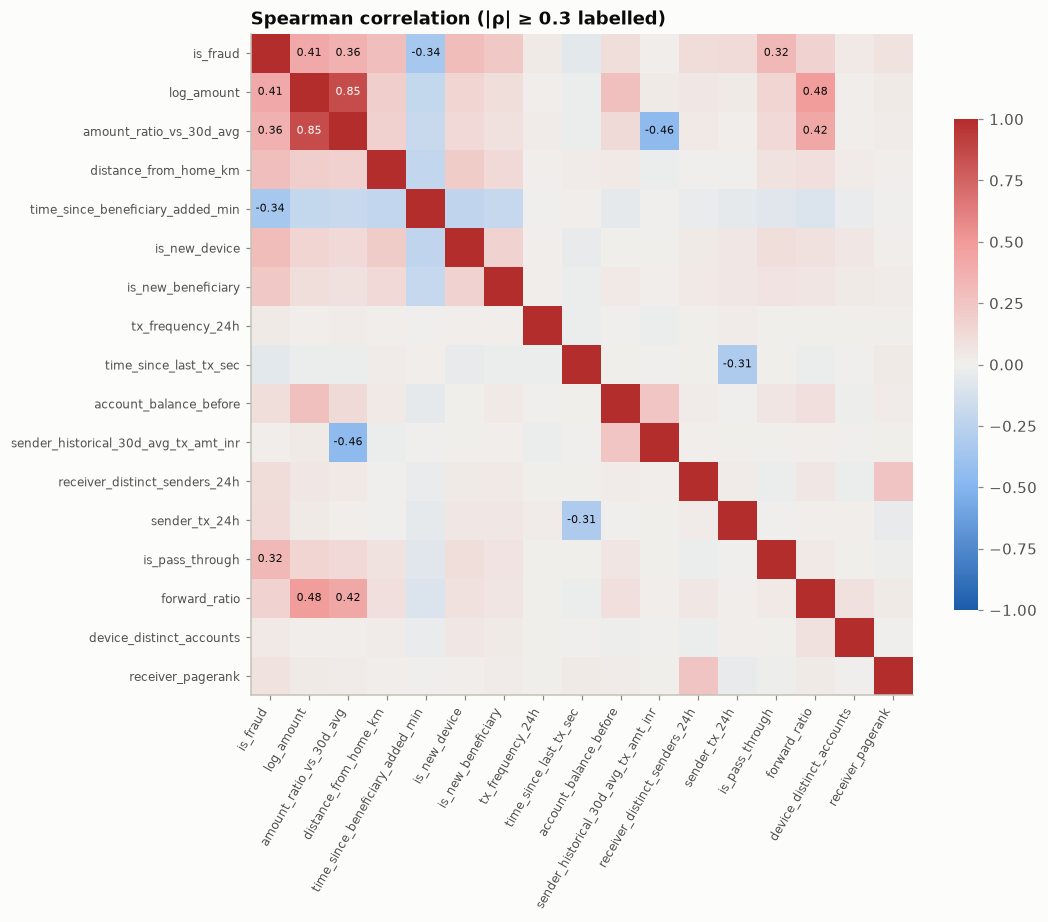

In [8]:
eda.fig_correlation(m11);

- `log_amount` ↔ `amount_ratio_vs_30d_avg` ρ = 0.85, so they're largely redundant. Distance-based models (KNN) should not get both unscaled.
- `forward_ratio` correlates with amount (0.48). Network features are otherwise **nearly uncorrelated** with behavioural ones, so they add *new* information (good news for Exp C).

,auc,mutual_info,group
log_amount,0.8499,0.1629,A transaction
amount_ratio_vs_30d_avg,0.8081,0.0886,B behavioural
time_since_beneficiary_added_min,0.7860,0.1082,B behavioural
distance_from_home_km,0.7388,0.1061,B behavioural
is_new_device,0.6766,0.0343,B behavioural
forward_ratio,0.6439,0.0680,C network
is_new_beneficiary,0.6391,0.0187,B behavioural
same_community,0.6069,0.0222,C network
sec_since_sender_last_inflow,0.5830,0.0405,C network
account_balance_before,0.5817,0.0159,A transaction


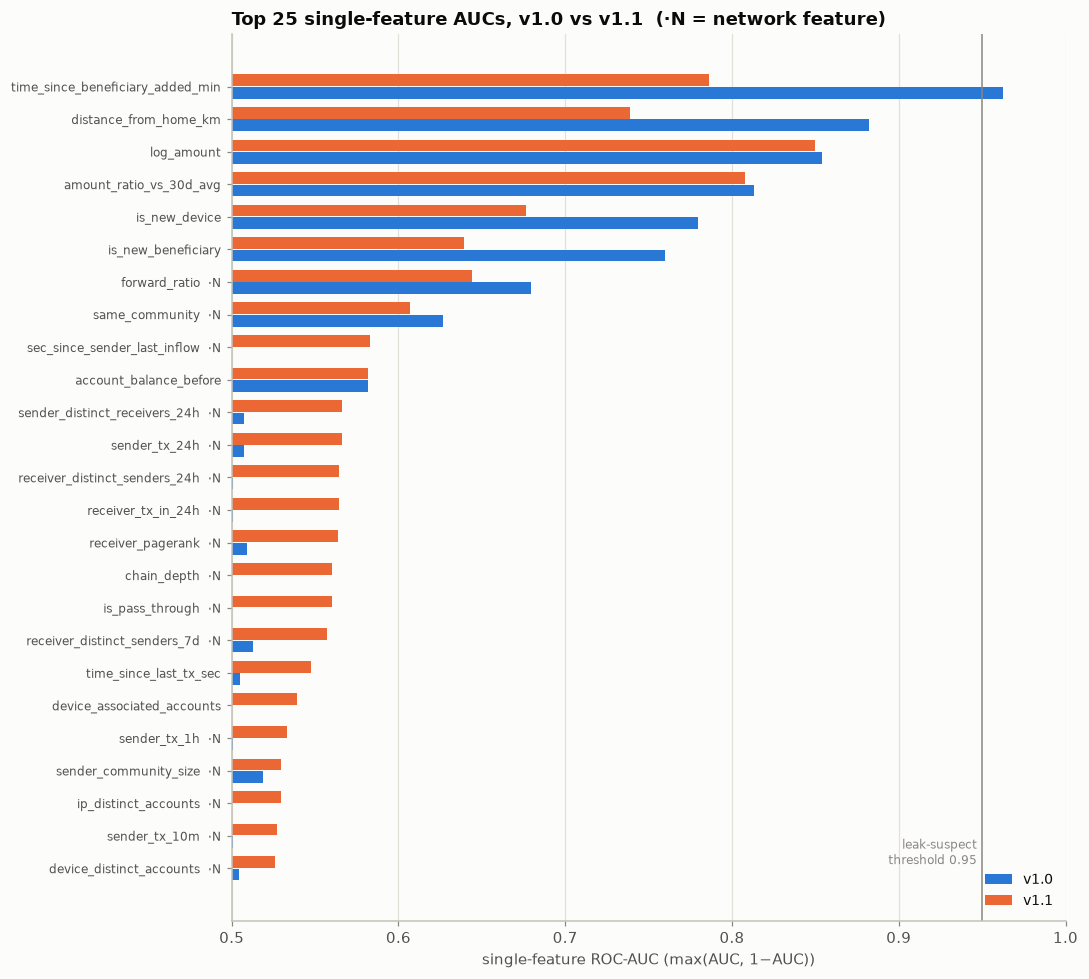

In [9]:
eda.fig_feature_auc(m10, m11)
rank = eda.feature_ranking(m11)
display(rank.head(15))

- **v1.0 → v1.1:** behavioural AUCs *drop* (e.g. `time_since_beneficiary_added_min` 0.96 → 0.79) because of the 50% camouflage, while network AUCs *rise* from ≈0.50 to 0.56–0.64. No feature crosses the 0.95 leak-suspect line in v1.1.
- Individually, network features are **weak** (AUC ≤ 0.64). Their value is **conditional**: they flag the fraud that behaviour misses (Section 6). Single-feature AUC understates them.

## 5 · Scenario fingerprints and the BORDERLINE problem

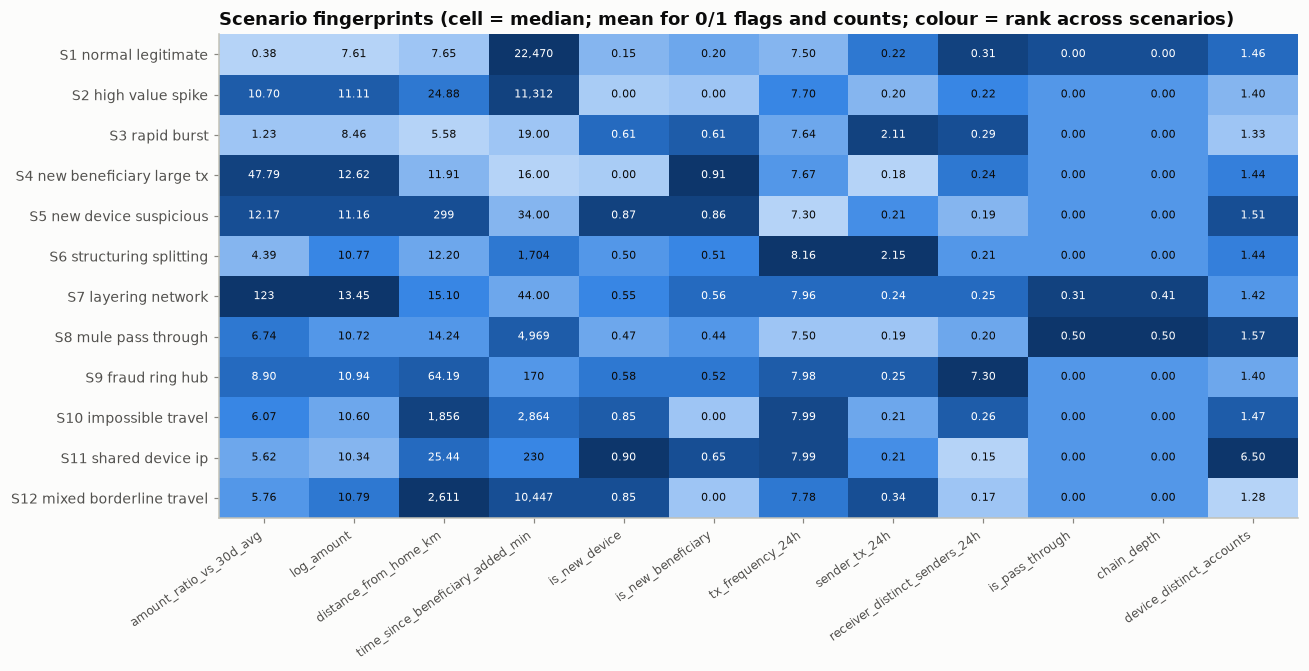

In [10]:
eda.fig_scenario_profile(m11);

Each scenario has a distinct fingerprint: S4 = new beneficiary + large ratio, S5 = new device + far, S10/S12 = extreme distance, S3/S6 = sender bursts, S7/S8 = pass-through chains, S9 = receiver fan-in, S11 = shared device. Per-scenario recall in Phase 5 (**RQ7**) is evaluated against these fingerprints.

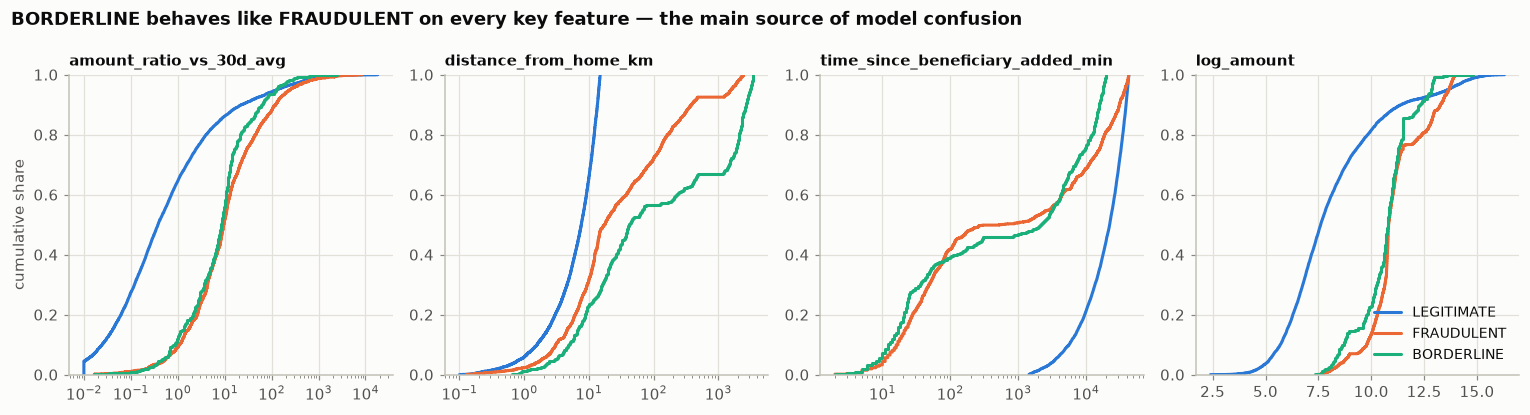

In [11]:
eda.fig_borderline_vs_fraud(m11);

**BORDERLINE and FRAUDULENT distributions almost overlap** on every key feature, while LEGITIMATE is clearly separate. Most model errors will therefore be *borderline ↔ fraud* confusion rather than legit ↔ fraud. Phase 5 will report it separately (and, as an extension, try 3-class `risk_label`).

## 6 · Network structure (v1.0 vs v1.1)

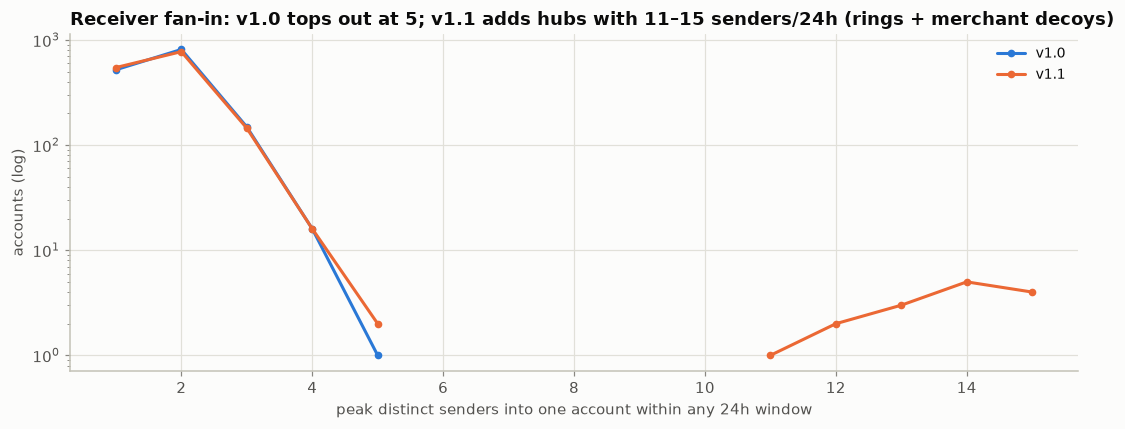

In [12]:
eda.fig_fanin_distribution(m10, m11);

v1.0 has **no account with more than 5 distinct senders in a day**, so there were no hubs at all. v1.1 adds 15 hubs with 11–15 senders/24h: **10 fraud-ring hubs and 5 clustered merchant decoys**, so fan-in alone cannot single out fraud.

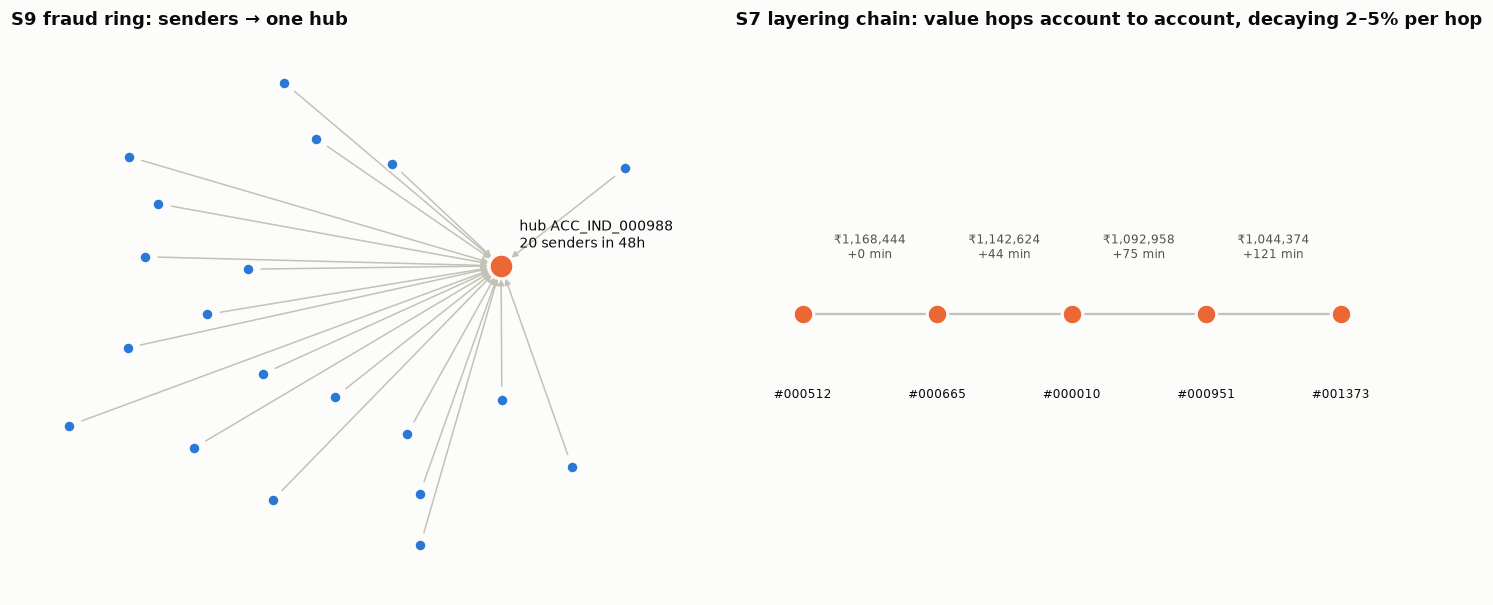

In [13]:
eda.fig_network_examples(m11, log);

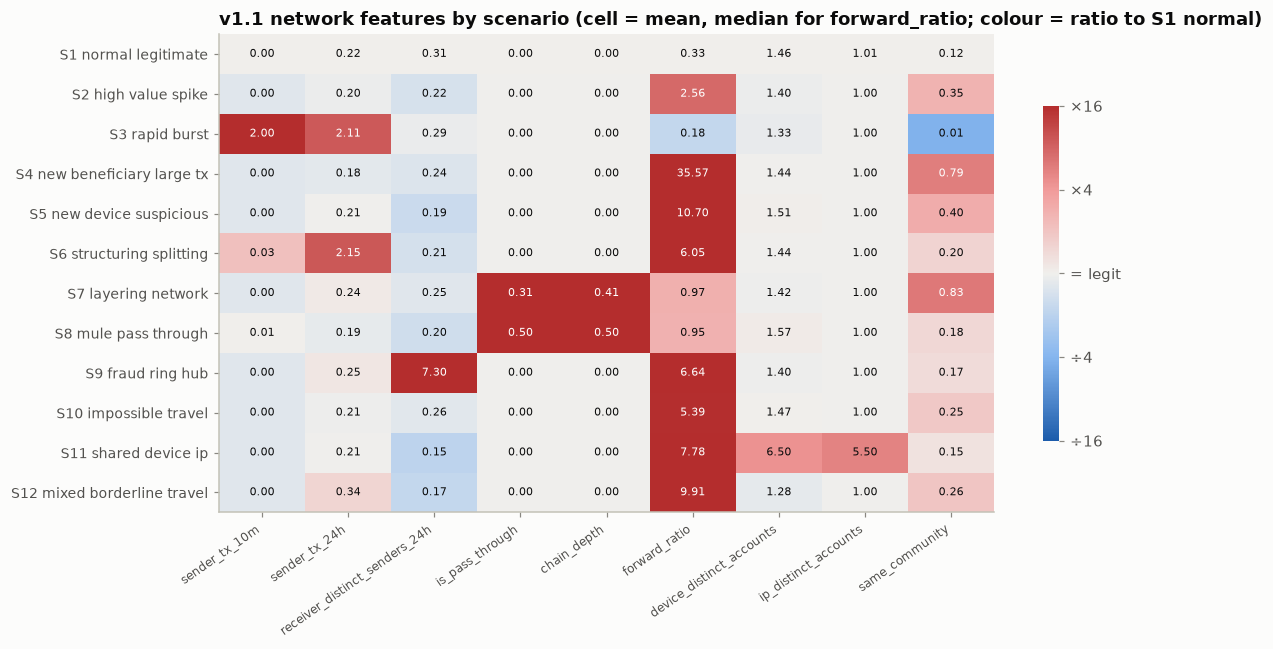

In [14]:
eda.fig_network_signal_by_scenario(m11);

Network signal appears **only where structure was injected**: bursts (S3, S6 → sender_tx), pass-through chains (S7, S8), ring fan-in (S9), shared devices (S11). Non-network scenarios stay at legit levels, so the injection is targeted, as designed.

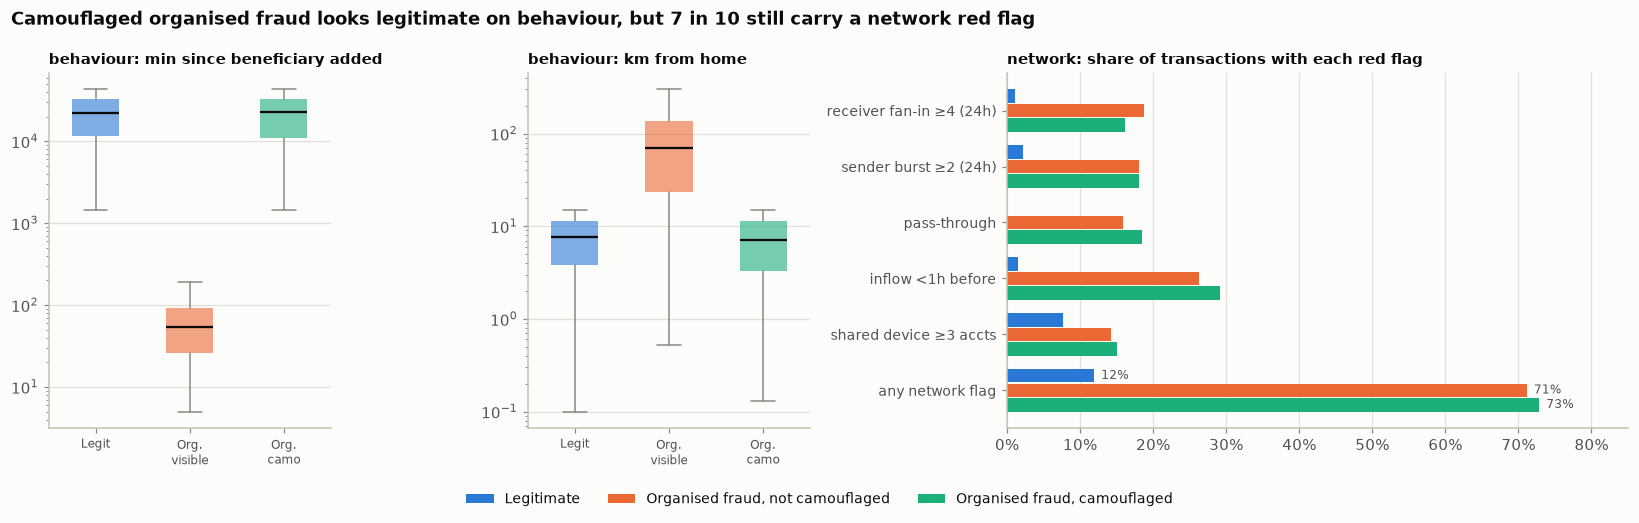

In [15]:
eda.fig_camouflage(m11, camo);

**Key result for RQ3:** camouflaged organised fraud is *indistinguishable from legitimate* on behaviour (beneficiary age, distance), yet **73% of it carries at least one network red flag vs 12% of legitimate transactions**. This is the gap Experiment C is expected to close.

## 7 · Summary

### RQ1: which features are most associated with suspicious activity?
| Rank | Feature | Group | AUC |
|---|---|---|---|
| 1 | `log_amount` | A transaction | 0.85 |
| 2 | `amount_ratio_vs_30d_avg` | B behavioural | 0.81 |
| 3 | `time_since_beneficiary_added_min` | B behavioural | 0.79 |
| 4 | `distance_from_home_km` | B behavioural | 0.74 |
| 5 | `is_new_device` | B behavioural | 0.68 |
| 6 | `forward_ratio` | C network | 0.64 |

1. **Amount relative to the customer's normal** is the strongest single signal; absolute amount depends on the channel.
2. **Behavioural context** (new/recent beneficiary, new device, distance from home) comes next. Two of these flags never fire on legitimate rows (a generator artifact).
3. **Network features** are individually weak but **orthogonal**: they catch camouflaged organised fraud (73% flagged vs 12% legit).
4. Channel, weekday and geography carry little signal; hour of day carries a modest one.

### Implications for later phases
| Phase | Implication |
|---|---|
| 4 Mining | Use the flag thresholds above; expect very high confidence for RECENT_BENEFICIARY / FAR_FROM_HOME rules (artifact). Include PASS_THROUGH, NEAR_THRESHOLD and the graph items. |
| 5 Supervised | Report PR-AUC/F1; analyse BORDERLINE separately; log-transform amounts; scale for KNN/MLP; use the temporal hold-out as a robustness check. |
| 6 Unsupervised | Expect clusters to separate legit vs {fraud ∪ borderline} but not fraud vs borderline. |
| 7 SHAP | Expect amount ratio, beneficiary age and distance on top, with network features rising for S7–S9 transactions. |

Figures: `reports/figures/eda_01 … eda_14`. Numbers: `reports/eda_summary.json`.